In [41]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit import transpile
from qiskit.visualization import plot_histogram

In [42]:
# Create quantum registers
q0 = QuantumRegister(1, name="q0")  # Destination
q1 = QuantumRegister(1, name="q1")  # Bell pair
q2 = QuantumRegister(1, name="q2")  # Source

# Create classical registers
crz = ClassicalRegister(1, name="crz")
crx = ClassicalRegister(1, name="crx")
cr_result = ClassicalRegister(1, name="result")

circuit = QuantumCircuit(q0, q1, q2, crz, crx, cr_result)

# Step 1: Initialize source qubit q2 in superposition
circuit.h(q2[0])
circuit.barrier()

# Step 2: Create Bell pair between q1 and q0
circuit.h(q1[0])
circuit.cx(q1[0], q0[0])
circuit.barrier()

# Step 3: Bell measurement operations
circuit.cx(q2[0], q1[0])
circuit.h(q2[0])
circuit.barrier()

# Step 4: Measure source and middle qubits
circuit.measure(q2[0], crz[0])
circuit.measure(q1[0], crx[0])
circuit.barrier()

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=3, num_clbits=0, params=[]), qubits=(<Qubit register=(1, "q0"), index=0>, <Qubit register=(1, "q1"), index=0>, <Qubit register=(1, "q2"), index=0>), clbits=())

In [43]:
# Step 5: Apply corrections to destination q0
with circuit.if_test((crx, 1)):
    circuit.x(q0[0])

with circuit.if_test((crz, 1)):
    circuit.z(q0[0])

circuit.barrier()


CircuitInstruction(operation=Instruction(name='barrier', num_qubits=3, num_clbits=0, params=[]), qubits=(<Qubit register=(1, "q0"), index=0>, <Qubit register=(1, "q1"), index=0>, <Qubit register=(1, "q2"), index=0>), clbits=())

In [44]:
# Step 6: Measure ONLY destination qubit q0
circuit.measure(q0[0], cr_result[0])

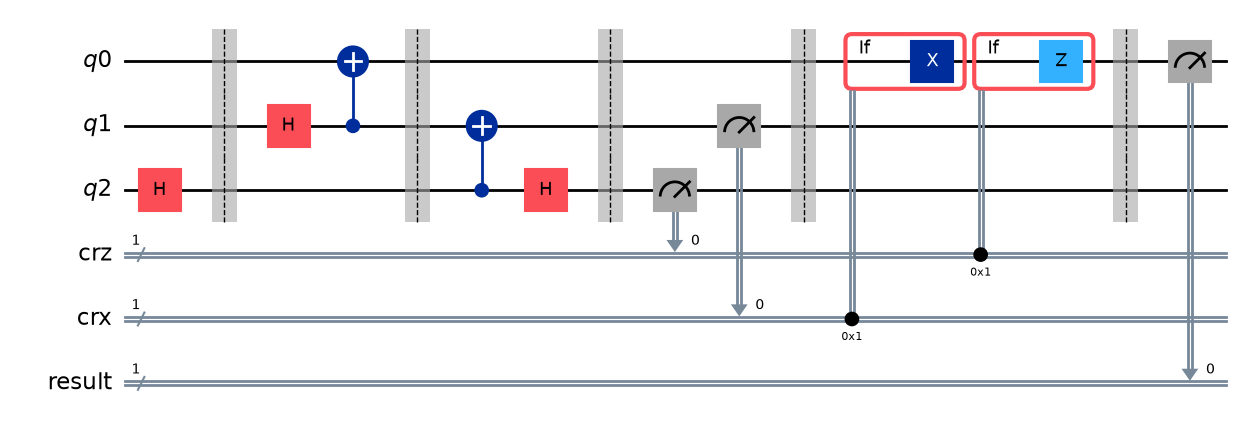

In [45]:

# Display circuit
circuit.draw(output="mpl")

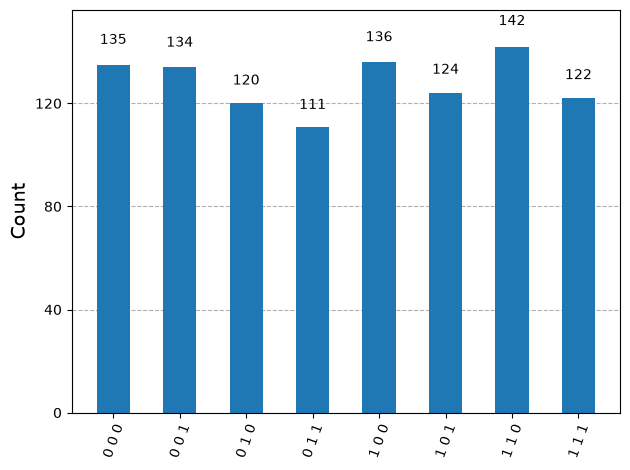

In [46]:
from qiskit_aer import AerSimulator

simulator = AerSimulator()

compiled_circuit = transpile(circuit, simulator)

result = simulator.run(
    compiled_circuit,
    shots=1024
).result()

counts = result.get_counts()

plot_histogram(counts)

qiskit_runtime_service._discover_account:WARNING:2026-11-22 16:41:36,282: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-22 16:41:39,753: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: quantum-computing-fundamentals quantum-computing-fundamentals. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-22 16:41:40,341: Loading instance: quantum-computing-fundamentals quantum-computing-fundamentals, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-22 16:41:42,793: Using 

Selected backend: ibm_kingston


qiskit_runtime_service.backends:WARNING:2026-11-22 16:41:44,002: Using instance: quantum-computing-fundamentals quantum-computing-fundamentals, plan: open


Job ID: dc1hmi6q4uuc73a3uio0


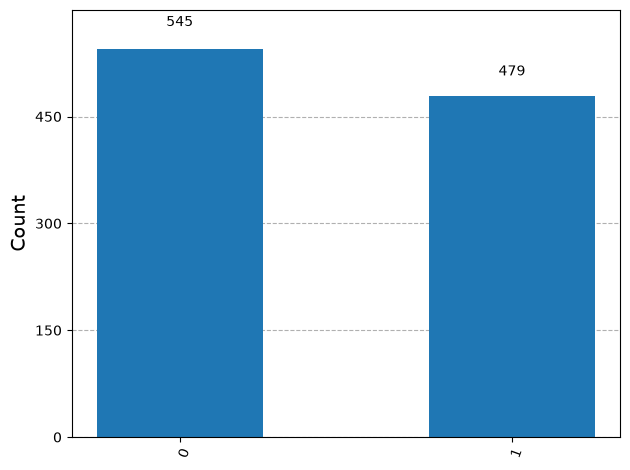

In [ ]:

from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

# Connect to IBM Quantum Platform
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token="my-token"
)

# Find an operational real quantum computer
backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=3
)

print("Selected backend:", backend.name)

# Transpile circuit for the selected backend
isa_circuit = transpile(
    circuit,
    backend=backend,
    optimization_level=1
)

# Run using Sampler V2
sampler = SamplerV2(mode=backend)

job = sampler.run(
    [isa_circuit],
    shots=1024
)

print("Job ID:", job.job_id())

# Retrieve results
job_result = job.result()

counts = job_result[0].data.result.get_counts()

plot_histogram(counts)
